In [1]:
# ============================================================
# SETUP
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import warnings
warnings.filterwarnings('ignore')

df_sales = pd.read_csv('data/processed/cleaned_retail_sales.csv')
df_sales['Order_Date'] = pd.to_datetime(df_sales['Order_Date'])

print(df_sales.shape)

(10000, 30)


In [2]:
# ============================================================
# RFM ANALYSIS
# ============================================================

analysis_date = df_sales['Order_Date'].max() + timedelta(days=1)
print("Analysis date (one day after last order):", analysis_date)

rfm = df_sales.groupby('Customer_ID').agg({
    'Order_Date': lambda x: (analysis_date - x.max()).days,
    'Order_ID': 'count',
    'Sales_Capped': 'sum'
}).reset_index()

rfm.columns = ['Customer_ID', 'Recency', 'Frequency', 'Monetary']

print("Number of unique customers:", len(rfm))
print(rfm.head(10))
print()
print(rfm[['Recency', 'Frequency', 'Monetary']].describe())

Analysis date (one day after last order): 2023-02-22 15:00:00
Number of unique customers: 1986
  Customer_ID  Recency  Frequency    Monetary
0    CUST0001       39          8  943.770842
1    CUST0002       25          6  617.531725
2    CUST0003       38          5  548.860692
3    CUST0004       87          3  247.117878
4    CUST0005      109          4  337.341185
5    CUST0006      100          4  523.077319
6    CUST0007       72          5  559.908437
7    CUST0008       77          5  530.193279
8    CUST0009       61          3  231.029445
9    CUST0010      178          5  557.306771

           Recency    Frequency     Monetary
count  1986.000000  1986.000000  1986.000000
mean     81.605740     5.035247   543.137452
std      77.074769     2.256983   282.191515
min       1.000000     1.000000    13.521954
25%      24.000000     3.000000   330.710807
50%      58.000000     5.000000   516.372006
75%     114.000000     6.000000   716.082448
max     408.000000    14.000000  1706.

In [3]:
# ============================================================
# RFM SCORING
# ============================================================

rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5])

rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

print(rfm[['Customer_ID', 'Recency', 'R_Score', 'Frequency', 'F_Score', 'Monetary', 'M_Score', 'RFM_Score']].head(10))

  Customer_ID  Recency R_Score  Frequency F_Score    Monetary M_Score  \
0    CUST0001       39       4          8       5  943.770842       5   
1    CUST0002       25       4          6       4  617.531725       4   
2    CUST0003       38       4          5       3  548.860692       3   
3    CUST0004       87       2          3       1  247.117878       1   
4    CUST0005      109       2          4       2  337.341185       2   
5    CUST0006      100       2          4       2  523.077319       3   
6    CUST0007       72       3          5       3  559.908437       3   
7    CUST0008       77       3          5       3  530.193279       3   
8    CUST0009       61       3          3       1  231.029445       1   
9    CUST0010      178       1          5       3  557.306771       3   

  RFM_Score  
0       455  
1       444  
2       433  
3       211  
4       222  
5       223  
6       333  
7       333  
8       311  
9       133  


In [4]:
# ============================================================
# CUSTOMER SEGMENT LABELING
# ============================================================

def assign_segment(row):
    r, f, m = int(row['R_Score']), int(row['F_Score']), int(row['M_Score'])

    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3 and m >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'New Customers'
    elif r <= 2 and f >= 3 and m >= 3:
        return 'At Risk'
    elif r <= 2 and f <= 2 and m <= 2:
        return 'Lost'
    else:
        return 'Potential Loyalists'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)

segment_summary = rfm.groupby('Segment').agg(
    Customer_Count=('Customer_ID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).sort_values('Customer_Count', ascending=False)

segment_summary['Pct_of_Customers'] = (segment_summary['Customer_Count'] / len(rfm) * 100).round(1)

print(segment_summary)

                     Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary  \
Segment                                                                         
Loyal Customers                 401    42.935162       6.184539    681.874482   
Lost                            373   181.375335       2.571046    246.372014   
Potential Loyalists             362    84.676796       3.972376    389.476482   
Champions                       353    19.439093       7.696884    856.457651   
At Risk                         278   126.348921       6.097122    697.895111   
New Customers                   219    20.817352       3.246575    347.066999   

                     Pct_of_Customers  
Segment                                
Loyal Customers                  20.2  
Lost                             18.8  
Potential Loyalists              18.2  
Champions                        17.8  
At Risk                          14.0  
New Customers                    11.0  


In [5]:
# ============================================================
# K-MEANS CLUSTERING — PREPARING AND SCALING THE DATA
# ============================================================

X = rfm[['Recency', 'Frequency', 'Monetary']].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Before scaling (first row):", X[0])
print("After scaling (first row):", X_scaled[0])
print()
print("Scaled means (should be ~0):", X_scaled.mean(axis=0).round(3))
print("Scaled std devs (should be ~1):", X_scaled.std(axis=0).round(3))

Before scaling (first row): [ 39.           8.         943.77084239]
After scaling (first row): [-0.55292375  1.3139223   1.42007917]

Scaled means (should be ~0): [-0. -0. -0.]
Scaled std devs (should be ~1): [1. 1. 1.]


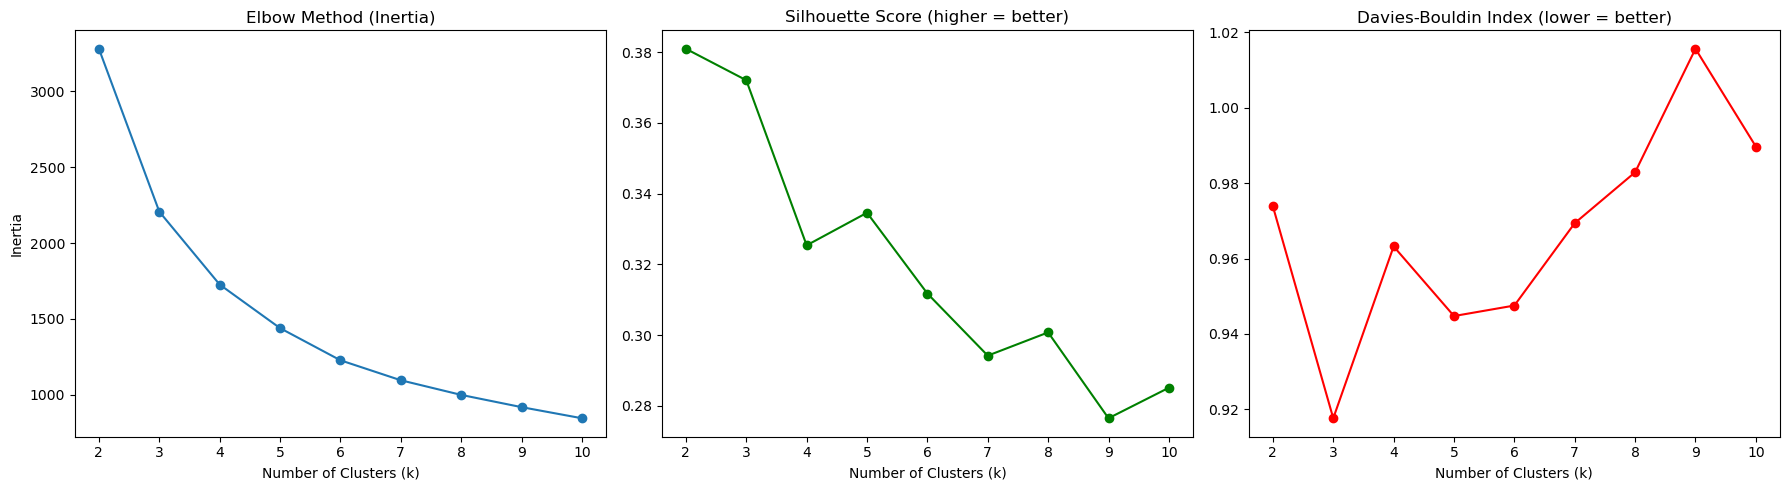

k=2: Inertia=3281.3, Silhouette=0.381, Davies-Bouldin=0.974
k=3: Inertia=2207.1, Silhouette=0.372, Davies-Bouldin=0.918
k=4: Inertia=1726.3, Silhouette=0.325, Davies-Bouldin=0.963
k=5: Inertia=1438.9, Silhouette=0.335, Davies-Bouldin=0.945
k=6: Inertia=1226.8, Silhouette=0.312, Davies-Bouldin=0.948
k=7: Inertia=1095.0, Silhouette=0.294, Davies-Bouldin=0.969
k=8: Inertia=998.5, Silhouette=0.301, Davies-Bouldin=0.983
k=9: Inertia=917.7, Silhouette=0.276, Davies-Bouldin=1.016
k=10: Inertia=844.4, Silhouette=0.285, Davies-Bouldin=0.990


In [7]:
# ============================================================
# K-MEANS — FINDING THE OPTIMAL NUMBER OF CLUSTERS
# ============================================================

inertias = []
sil_scores = []
db_scores = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(k_range, inertias, marker='o')
axes[0].set_title('Elbow Method (Inertia)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_range, sil_scores, marker='o', color='green')
axes[1].set_title('Silhouette Score (higher = better)')
axes[1].set_xlabel('Number of Clusters (k)')

axes[2].plot(k_range, db_scores, marker='o', color='red')
axes[2].set_title('Davies-Bouldin Index (lower = better)')
axes[2].set_xlabel('Number of Clusters (k)')

plt.tight_layout()
plt.show()

for k, inertia, sil, db in zip(k_range, inertias, sil_scores, db_scores):
    print(f"k={k}: Inertia={inertia:.1f}, Silhouette={sil:.3f}, Davies-Bouldin={db:.3f}")

In [8]:
# ============================================================
# K-MEANS — FINAL MODEL AND CLUSTER PROFILING
# ============================================================

optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm['Cluster'] = kmeans_final.fit_predict(X_scaled)

cluster_profile = rfm.groupby('Cluster').agg(
    Customer_Count=('Customer_ID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(1)

cluster_profile['Pct_of_Customers'] = (cluster_profile['Customer_Count'] / len(rfm) * 100).round(1)

print(cluster_profile)

         Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary  \
Cluster                                                             
0                   374        209.3            3.0         307.2   
1                   958         55.0            4.1         424.1   
2                   654         47.5            7.5         852.4   

         Pct_of_Customers  
Cluster                    
0                    18.8  
1                    48.2  
2                    32.9  


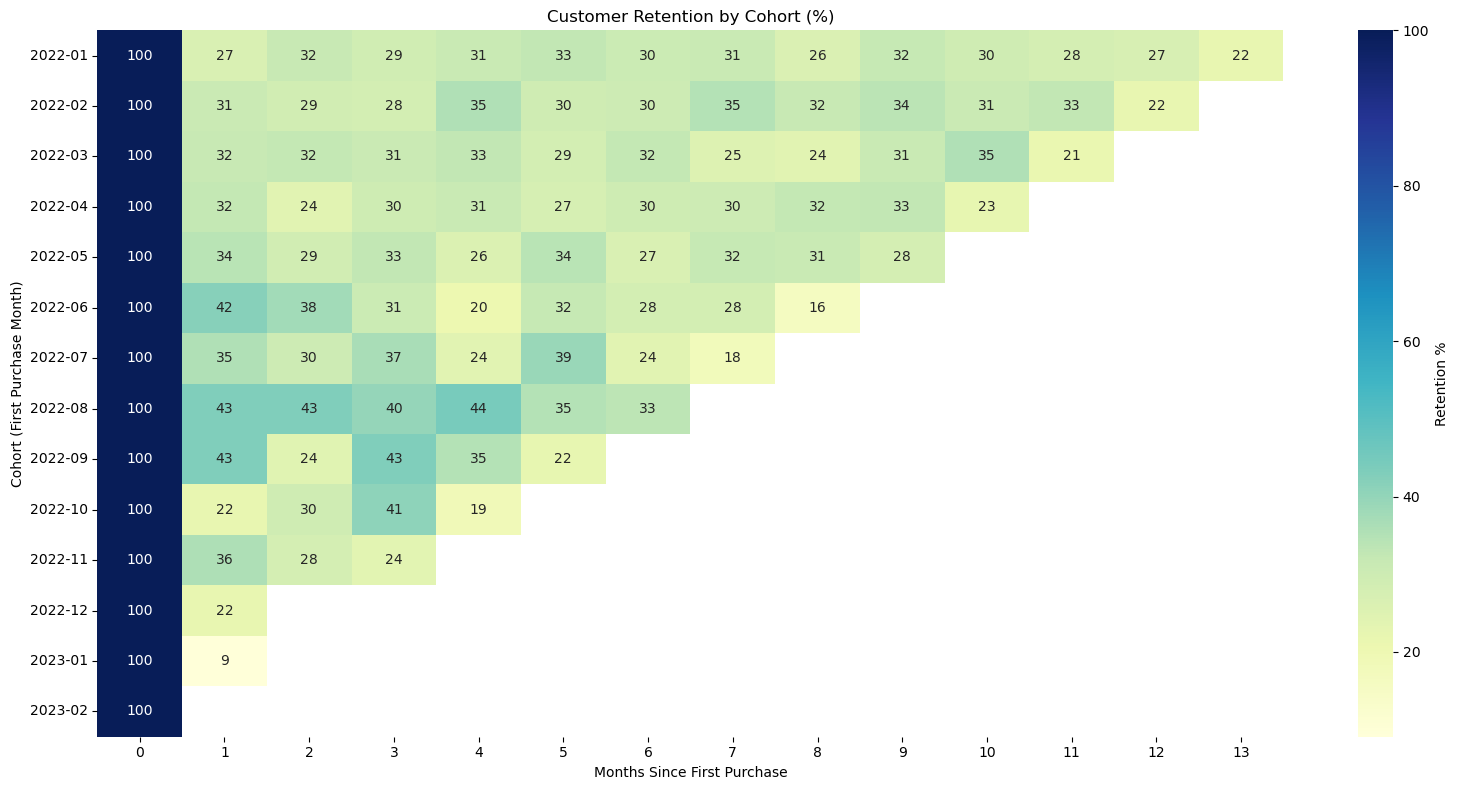

In [9]:
# ============================================================
# COHORT ANALYSIS
# ============================================================

df_cohort = df_sales.copy()
df_cohort['Order_Month'] = df_cohort['Order_Date'].dt.to_period('M')
df_cohort['Cohort'] = df_cohort.groupby('Customer_ID')['Order_Date'].transform('min').dt.to_period('M')
df_cohort['Cohort_Index'] = (df_cohort['Order_Month'] - df_cohort['Cohort']).apply(lambda x: x.n)

cohort_size = df_cohort.groupby('Cohort')['Customer_ID'].nunique()
retention = df_cohort.groupby(['Cohort', 'Cohort_Index'])['Customer_ID'].nunique().reset_index()
retention_matrix = retention.pivot(index='Cohort', columns='Cohort_Index', values='Customer_ID')
retention_rate = retention_matrix.divide(cohort_size, axis=0) * 100

plt.figure(figsize=(16, 8))
sns.heatmap(retention_rate, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'Retention %'})
plt.title('Customer Retention by Cohort (%)')
plt.xlabel('Months Since First Purchase')
plt.ylabel('Cohort (First Purchase Month)')
plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# CUSTOMER LIFETIME VALUE (CLV)
# ============================================================

cust = df_sales.groupby('Customer_ID').agg(
    Total_Revenue=('Sales_Capped', 'sum'),
    Order_Count=('Order_ID', 'count'),
    First_Purchase=('Order_Date', 'min'),
    Last_Purchase=('Order_Date', 'max')
).reset_index()

cust['Lifespan_Days'] = (cust['Last_Purchase'] - cust['First_Purchase']).dt.days.replace(0, 1)
cust['Avg_Order_Value'] = cust['Total_Revenue'] / cust['Order_Count']
cust['Purchase_Frequency'] = cust['Order_Count'] / (cust['Lifespan_Days'] / 365.25)
cust['CLV_Simple'] = cust['Avg_Order_Value'] * cust['Purchase_Frequency'] * 3

print(cust[['Customer_ID', 'Total_Revenue', 'Order_Count', 'Avg_Order_Value', 'Purchase_Frequency', 'CLV_Simple']].describe())
print()
print("Top 10 customers by projected CLV:")
print(cust.sort_values('CLV_Simple', ascending=False)[['Customer_ID', 'Avg_Order_Value', 'Purchase_Frequency', 'CLV_Simple']].head(10))

       Total_Revenue  Order_Count  Avg_Order_Value  Purchase_Frequency  \
count    1986.000000  1986.000000      1986.000000         1986.000000   
mean      543.137452     5.035247       107.910714           23.388656   
std       282.191515     2.256983        33.371903           71.913504   
min        13.521954     1.000000        13.521954            1.892487   
25%       330.710807     3.000000        85.927239            5.576336   
50%       516.372006     5.000000       104.760308            7.454082   
75%       716.082448     6.000000       126.189521            9.938776   
max      1706.776827    14.000000       275.332406          730.500000   

          CLV_Simple  
count    1986.000000  
mean     7521.286062  
std     27172.675182  
min       253.804359  
25%      1701.373520  
50%      2340.984912  
75%      3334.635156  
max    301695.484146  

Top 10 customers by projected CLV:
     Customer_ID  Avg_Order_Value  Purchase_Frequency     CLV_Simple
316     CUST0319     

In [11]:
# ============================================================
# CLV — FIXING THE PURCHASE FREQUENCY EDGE CASE
# ============================================================

# How many customers are affected?
same_day_customers = (cust['Lifespan_Days'] <= 1).sum()
print(f"Customers with <=1 day lifespan: {same_day_customers} ({same_day_customers/len(cust)*100:.1f}%)")

# Floor the lifespan window used for annualizing at 30 days.
# We only ever *observed* this customer within the dataset's timeframe --
# a 1-day observation window is never a reliable basis for estimating an annual rate.
cust['Lifespan_Days_Adj'] = cust['Lifespan_Days'].clip(lower=30)
cust['Purchase_Frequency'] = cust['Order_Count'] / (cust['Lifespan_Days_Adj'] / 365.25)
cust['CLV_Simple'] = cust['Avg_Order_Value'] * cust['Purchase_Frequency'] * 3

print(cust[['Total_Revenue', 'Order_Count', 'Avg_Order_Value', 'Purchase_Frequency', 'CLV_Simple']].describe())
print()
print("Top 10 customers by projected CLV (corrected):")
print(cust.sort_values('CLV_Simple', ascending=False)[['Customer_ID', 'Order_Count', 'Avg_Order_Value', 'Purchase_Frequency', 'CLV_Simple']].head(10))

Customers with <=1 day lifespan: 75 (3.8%)
       Total_Revenue  Order_Count  Avg_Order_Value  Purchase_Frequency  \
count    1986.000000  1986.000000      1986.000000         1986.000000   
mean      543.137452     5.035247       107.910714            8.522430   
std       282.191515     2.256983        33.371903            4.810178   
min        13.521954     1.000000        13.521954            1.892487   
25%       330.710807     3.000000        85.927239            5.576336   
50%       516.372006     5.000000       104.760308            7.454082   
75%       716.082448     6.000000       126.189521            9.938776   
max      1706.776827    14.000000       275.332406           48.700000   

         CLV_Simple  
count   1986.000000  
mean    2750.698286  
std     1882.573721  
min      253.804359  
25%     1682.904294  
50%     2309.348460  
75%     3226.809106  
max    24070.295060  

Top 10 customers by projected CLV (corrected):
     Customer_ID  Order_Count  Avg_Order_Val

In [12]:
# ============================================================
# SAVING PHASE 4 OUTPUTS
# ============================================================

rfm.to_csv('data/processed/rfm_analysis.csv', index=False)
cust.to_csv('data/processed/customer_clv.csv', index=False)
retention_rate.to_csv('data/processed/cohort_retention.csv')

print("Saved rfm_analysis.csv:", rfm.shape)
print("Saved customer_clv.csv:", cust.shape)
print("Saved cohort_retention.csv:", retention_rate.shape)

Saved rfm_analysis.csv: (1986, 10)
Saved customer_clv.csv: (1986, 10)
Saved cohort_retention.csv: (14, 14)
